# Notebook 05 — Comparison: Logistic Regression vs Random Forest

**Authors:** K.G.L. Sandeepa (MS26929378) · Kusal Dissanayake (MS26929064)

The two algorithms were developed separately — Logistic Regression in notebook 03, Random
Forest in notebook 04 — each tuned by cross-validation on the **development set only**, with the
885-row test set sealed. This notebook brings them together and does the one thing neither of
the others was allowed to: it **touches the test set exactly once**, with every modelling
decision already frozen.

It answers four questions:

1. **On cross-validation, how do the two compare** across the four feature variants? (loaded
   from `lr_cv_results.csv` and `rf_cv_results.csv`).
2. **On the sealed test set, which wins** on the three-class problem, and where?
3. **On the binary Dropout-vs-rest problem**, how do their ROC/PR curves and thresholds differ?
4. **What does each tell us** — Logistic Regression's coefficients against Random Forest's
   feature importances — and what should the report recommend?

Nothing here is tuned on the test set. The tuned configurations are loaded from the JSON the two
model notebooks saved, rebuilt on the shared `src/` pipeline, fitted on the development set, and
scored once.

## 1 · Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import data
import preprocess
import evaluation as ev
import viz

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
viz.set_accessible_style()

FIGURES = ROOT / "reports" / "figures"
PROC = ROOT / "data" / "processed"
FIGURES.mkdir(parents=True, exist_ok=True)

X_dev, X_test, y_dev, y_test = data.make_splits()
CLASSES = ev.CLASS_ORDER
MODEL_COLORS = {"Logistic Regression": viz.OKABE_ITO["blue"],
                "Random Forest": viz.OKABE_ITO["vermillion"]}

lr_params = json.load(open(PROC / "lr_best_params.json"))
rf_params = json.load(open(PROC / "rf_best_params.json"))
print("tuned Logistic Regression:", lr_params)
print("tuned Random Forest      :", rf_params)
print("\ndevelopment rows:", len(X_dev), "| sealed test rows:", len(X_test))

tuned Logistic Regression: {'C': 0.1, 'class_weight': 'balanced', 'pca_components': 13}
tuned Random Forest      : {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 300}

development rows: 3539 | sealed test rows: 885


## 2 · Development-set comparison (cross-validated)

The tables the two model notebooks saved, stacked. Every row is 5-fold cross-validated on the
same 3,539 development rows, so Logistic Regression and Random Forest are measured on identical
data and the numbers line up directly.

In [2]:
lr_cv = pd.read_csv(PROC / "lr_cv_results.csv")
rf_cv = pd.read_csv(PROC / "rf_cv_results.csv")
cv_all = pd.concat([lr_cv[lr_cv.model != "Majority baseline"],
                    rf_cv[rf_cv.model != "Majority baseline"]], ignore_index=True)

show = ["model", "variant", "accuracy", "balanced_accuracy", "f1_macro", "mcc",
        "roc_auc", "recall_dropout", "recall_enrolled", "recall_graduate"]
print("5-fold cross-validation on the development set:\n")
print(cv_all[show].round(4).to_string(index=False))

5-fold cross-validation on the development set:

              model      variant  accuracy  balanced_accuracy  f1_macro    mcc  roc_auc  recall_dropout  recall_enrolled  recall_graduate
Logistic Regression all features    0.7547             0.7208    0.7136 0.6113   0.8885          0.7335           0.6079           0.8212
Logistic Regression      reduced    0.7553             0.7252    0.7165 0.6138   0.8887          0.7247           0.6315           0.8195
Logistic Regression          pca    0.7480             0.7190    0.7097 0.6030   0.8831          0.7274           0.6236           0.8059
Logistic Regression 1st sem only    0.7268             0.6932    0.6860 0.5682   0.8620          0.7115           0.5780           0.7900
      Random Forest all features    0.7720             0.7273    0.7260 0.6322   0.8912          0.7449           0.5780           0.8591
      Random Forest      reduced    0.7609             0.7155    0.7133 0.6157   0.8857          0.7353           0.5622   

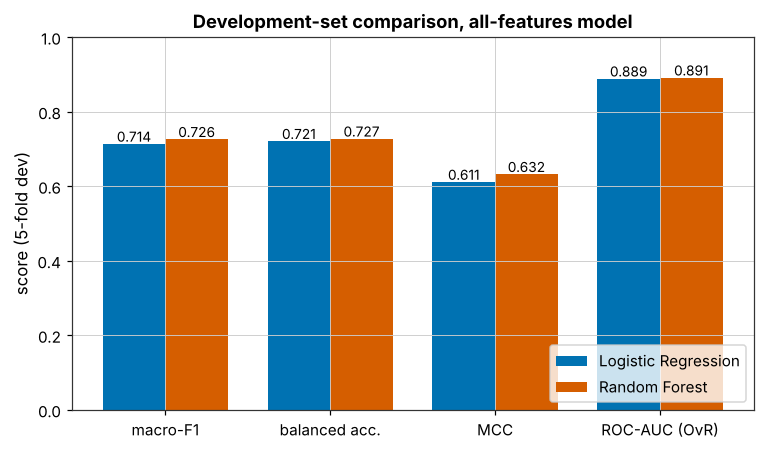

In [3]:
# Headline (all-features) comparison across the metrics that matter.
head = cv_all[cv_all.variant == "all features"].set_index("model")
metrics = ["f1_macro", "balanced_accuracy", "mcc", "roc_auc"]
fig, ax = plt.subplots(figsize=(8, 4.4))
x = np.arange(len(metrics)); w = 0.38
for i, model in enumerate(["Logistic Regression", "Random Forest"]):
    vals = [head.loc[model, m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=model, color=MODEL_COLORS[model])
    for rect, v in zip(bars, vals):
        ax.text(rect.get_x() + rect.get_width()/2, v + 0.006, f"{v:.3f}",
                ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["macro-F1", "balanced acc.", "MCC", "ROC-AUC (OvR)"])
ax.set_ylim(0, 1.0); ax.set_ylabel("score (5-fold dev)")
ax.set_title("Development-set comparison, all-features model")
ax.legend(loc="lower right")
fig.savefig(FIGURES / "05_dev_metric_comparison.png")
plt.show()

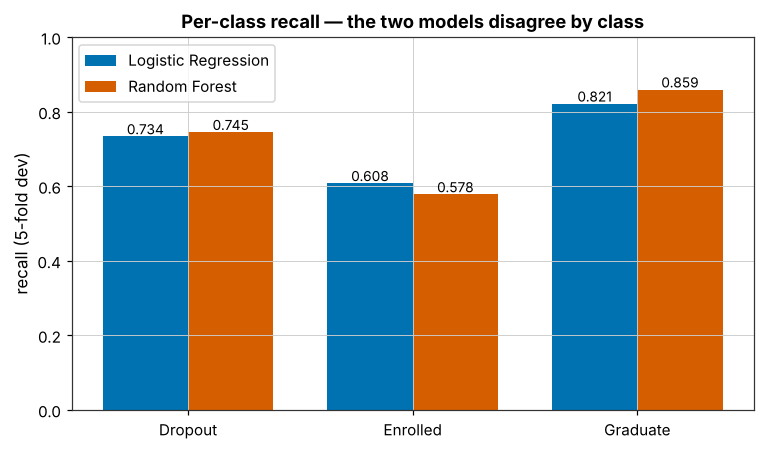

In [4]:
# Per-class recall: where the two models genuinely differ.
recalls = ["recall_dropout", "recall_enrolled", "recall_graduate"]
labels = ["Dropout", "Enrolled", "Graduate"]
fig, ax = plt.subplots(figsize=(8, 4.4))
x = np.arange(len(recalls)); w = 0.38
for i, model in enumerate(["Logistic Regression", "Random Forest"]):
    vals = [head.loc[model, r] for r in recalls]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=model, color=MODEL_COLORS[model])
    for rect, v in zip(bars, vals):
        ax.text(rect.get_x() + rect.get_width()/2, v + 0.006, f"{v:.3f}",
                ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.0); ax.set_ylabel("recall (5-fold dev)")
ax.set_title("Per-class recall — the two models disagree by class")
ax.legend(loc="upper left")
fig.savefig(FIGURES / "05_dev_recall_by_class.png")
plt.show()

**What the development numbers say.** Random Forest is a little ahead overall — higher macro-F1
and MCC — and the gap is almost entirely in the **Graduate** and **Dropout** classes. Logistic
Regression is the stronger of the two on **Enrolled**, the smallest and hardest class, because its
balanced class weights push harder on the minority than the forest's bootstrap sampling does. The
two models are complementary rather than one strictly dominating.

## 3 · The sealed test set — three-class, touched once

With every decision frozen, each tuned model is rebuilt on the shared pipeline, fitted on the full
development set, and scored **once** on the 885 held-out rows. This is the number the report quotes.

In [5]:
def lr_model():
    return LogisticRegression(C=lr_params["C"], class_weight=lr_params["class_weight"],
                              max_iter=5000, random_state=data.RANDOM_STATE)

def rf_model():
    return RandomForestClassifier(
        n_estimators=rf_params["n_estimators"], max_depth=rf_params["max_depth"],
        min_samples_leaf=rf_params["min_samples_leaf"], max_features=rf_params["max_features"],
        class_weight=rf_params["class_weight"], random_state=data.RANDOM_STATE, n_jobs=-1)

tuned = {
    "Logistic Regression": preprocess.build_pipeline(lr_model(), variant="all"),
    "Random Forest": preprocess.build_pipeline(rf_model(), variant="all"),
}

rows = [ev.majority_baseline(y_dev, y_test)]
fitted, preds = {}, {}
for name, pipe in tuned.items():
    pipe.fit(X_dev, y_dev)                     # fit on development data only
    fitted[name] = pipe
    preds[name] = pipe.predict(X_test)         # the single look at the test set
    rows.append(ev.evaluate_model(pipe, X_dev, y_dev, X_test, y_test, name=name,
                                  variant="all features", task="multiclass",
                                  balancing="class_weight"))

final3 = ev.results_table(rows)
cols = ["model", "accuracy", "balanced_accuracy", "precision_macro", "recall_macro",
        "f1_macro", "mcc", "roc_auc", "recall_dropout", "recall_enrolled", "recall_graduate"]
print("FINAL TEST — three-class (885 rows):\n")
print(final3[cols].round(4).to_string(index=False))

FINAL TEST — three-class (885 rows):

              model  accuracy  balanced_accuracy  precision_macro  recall_macro  f1_macro    mcc  roc_auc  recall_dropout  recall_enrolled  recall_graduate
  Majority baseline    0.4994             0.3333           0.1665        0.3333    0.2221 0.0000      NaN          0.0000           0.0000           1.0000
Logistic Regression    0.7220             0.6948           0.6918        0.6948    0.6834 0.5701   0.8849          0.6831           0.6164           0.7851
      Random Forest    0.7582             0.7187           0.7182        0.7187    0.7142 0.6141   0.8894          0.7148           0.5975           0.8439


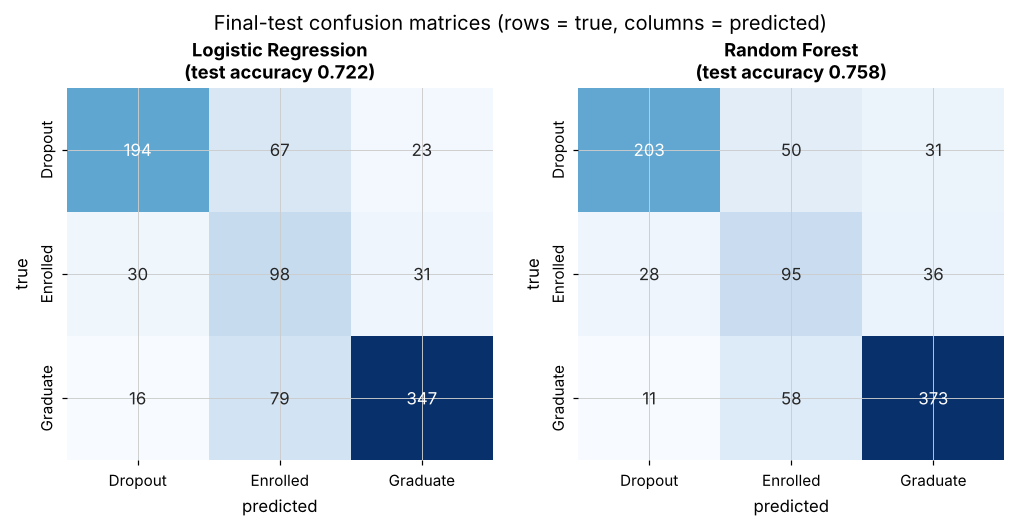

In [6]:
# Side-by-side confusion matrices on the sealed test set.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, name in zip(axes, tuned):
    cm = ev.confusion_frame(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap=viz.SEQUENTIAL, cbar=False, ax=ax,
                annot_kws={"fontsize": 11})
    acc = (preds[name] == y_test.values).mean()
    ax.set_title(f"{name}\n(test accuracy {acc:.3f})")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.suptitle("Final-test confusion matrices (rows = true, columns = predicted)", y=1.04)
fig.savefig(FIGURES / "05_test_confusion.png")
plt.show()

## 4 · The sealed test set — binary, Dropout vs rest

The binary labels are derived from the **same** split, so no new division of the data is
introduced. Each model is refitted with balanced class weights and scored once; the ROC and PR
curves put both models on one axis.

In [7]:
yb_dev = (y_dev == "Dropout").astype(int)
yb_test = (y_test == "Dropout").astype(int)
base_rate = yb_test.mean()

bin_rows, bin_fitted = [], {}
for name, factory in [("Logistic Regression", lr_model), ("Random Forest", rf_model)]:
    pipe = preprocess.build_pipeline(factory(), variant="all")
    bin_rows.append(ev.evaluate_model(pipe, X_dev, yb_dev, X_test, yb_test, name=name,
                                      variant="all features", task="binary",
                                      balancing="class_weight"))
    bin_fitted[name] = pipe          # fitted inside evaluate_model

finalb = ev.results_table(bin_rows)
print("FINAL TEST — binary Dropout vs rest (positive rate %.3f):\n" % base_rate)
print(finalb[["model", "accuracy", "f1_macro", "mcc", "roc_auc", "pr_auc",
              "recall_dropout"]].round(4).to_string(index=False))

FINAL TEST — binary Dropout vs rest (positive rate 0.321):

              model  accuracy  f1_macro    mcc  roc_auc  pr_auc  recall_dropout
Logistic Regression    0.8599    0.8418 0.6845   0.9165  0.8822          0.8134
      Random Forest    0.8768    0.8586 0.7172   0.9156  0.8711          0.8063


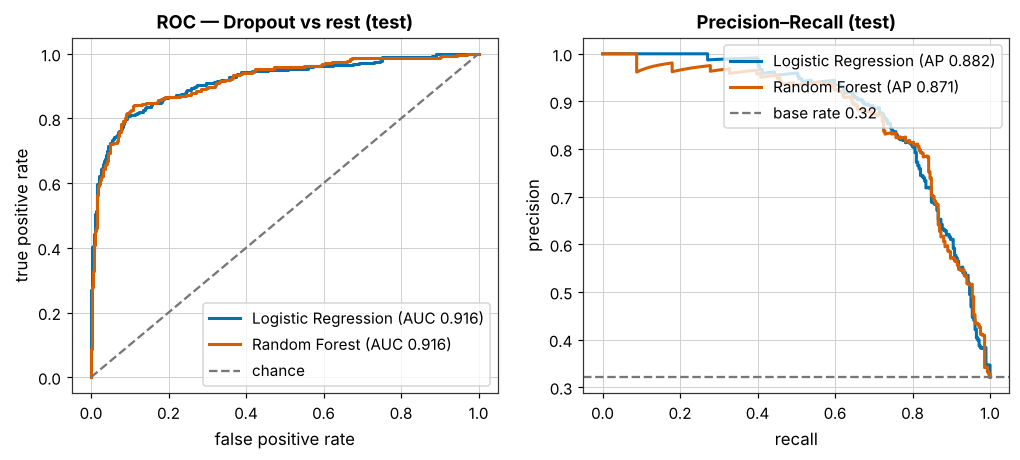

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for name in bin_fitted:
    p = bin_fitted[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(yb_test, p)
    prec, rec, _ = precision_recall_curve(yb_test, p)
    c = MODEL_COLORS[name]
    ax[0].plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(yb_test,p):.3f})")
    ax[1].plot(rec, prec, color=c, lw=2, label=f"{name} (AP {average_precision_score(yb_test,p):.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", color="#777777", label="chance")
ax[0].set_title("ROC — Dropout vs rest (test)"); ax[0].set_xlabel("false positive rate")
ax[0].set_ylabel("true positive rate"); ax[0].legend(loc="lower right")
ax[1].axhline(base_rate, ls="--", color="#777777", label=f"base rate {base_rate:.2f}")
ax[1].set_title("Precision–Recall (test)"); ax[1].set_xlabel("recall")
ax[1].set_ylabel("precision"); ax[1].legend(loc="upper right")
fig.savefig(FIGURES / "05_test_roc_pr.png")
plt.show()

## 5 · What each model actually used

The two algorithms justify their predictions in different currencies. Logistic Regression gives a
signed, standardised coefficient per feature — a direction and a size. Random Forest gives a
non-negative importance — how much a feature reduced impurity, with no direction. Putting the two
rankings next to each other is the heart of the comparison: where they agree is a robust finding,
and where they disagree is usually explained by the forest's known bias toward high-cardinality
and continuous features.

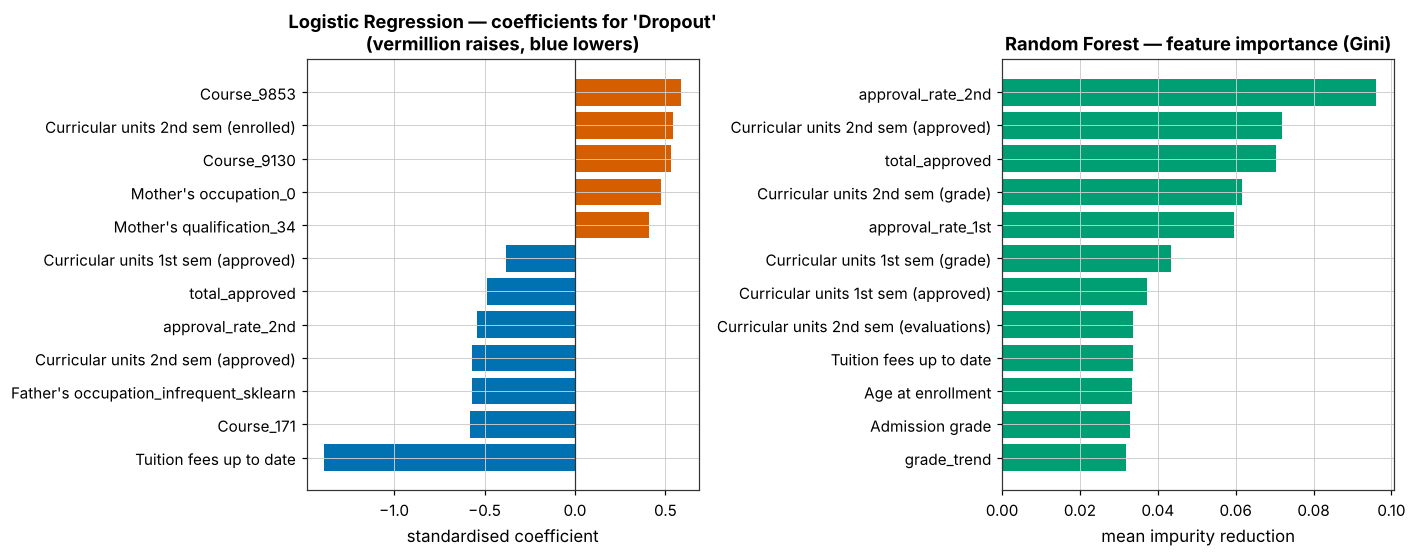

In [9]:
# Logistic Regression: signed coefficients for the Dropout class.
lrf = fitted["Logistic Regression"]
names = lrf.named_steps["prep"].get_feature_names_out()
clf = lrf.named_steps["model"]
di = list(clf.classes_).index("Dropout")
coef = pd.Series(clf.coef_[di], index=names)
lr_top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).sort_values()

# Random Forest: impurity importances.
rff = fitted["Random Forest"]
imp = pd.Series(rff.named_steps["model"].feature_importances_,
                index=rff.named_steps["prep"].get_feature_names_out())
rf_top = imp.sort_values(ascending=False).head(12).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
colors = [viz.POS if v > 0 else viz.NEG for v in lr_top.values]
axes[0].barh(lr_top.index, lr_top.values, color=colors)
axes[0].axvline(0, color="#333333", lw=0.8)
axes[0].set_title("Logistic Regression — coefficients for 'Dropout'\n(vermillion raises, blue lowers)")
axes[0].set_xlabel("standardised coefficient")
axes[1].barh(rf_top.index, rf_top.values, color=viz.OKABE_ITO["green"])
axes[1].set_title("Random Forest — feature importance (Gini)")
axes[1].set_xlabel("mean impurity reduction")
fig.tight_layout()
fig.savefig(FIGURES / "05_interpretability.png")
plt.show()

In [10]:
# Do the two agree on the paper's five cross-algorithm features?
paper = ["Curricular units 2nd sem (approved)", "Curricular units 1st sem (approved)",
         "Curricular units 2nd sem (grade)", "Course", "Tuition fees up to date"]
lr_rank = coef.abs().rank(ascending=False)
rf_rank = imp.rank(ascending=False)
print(f"{'feature':42s} {'LR |coef| rank':>15s} {'RF importance rank':>19s}")
for name in paper:
    lh = [n for n in names if n.startswith(name)]
    lr_r = int(lr_rank[lh].min()) if lh else None
    rf_r = int(rf_rank[lh].min()) if lh else None
    print(f"{name:42s} {str(lr_r):>15s} {str(rf_r):>19s}")

feature                                     LR |coef| rank  RF importance rank
Curricular units 2nd sem (approved)                      5                   2
Curricular units 1st sem (approved)                     12                   7
Curricular units 2nd sem (grade)                       102                   4
Course                                                   2                  36
Tuition fees up to date                                  1                   9


## 6 · Dimensionality reduction across both models

The all-features model and the PCA model, for each algorithm, from the cross-validation tables.
PCA standardises the continuous block and replaces its 23 columns with 13 components (95% of the
variance). The point of the comparison is that compression costs almost nothing on score — and
everything on interpretability, since a principal component is a blend of features with no
coefficient or importance a support office could act on.

macro-F1, all features vs PCA (5-fold dev):

variant              all features     pca  delta (pca - all)
model                                                       
Logistic Regression        0.7136  0.7097            -0.0039
Random Forest              0.7260  0.7155            -0.0105


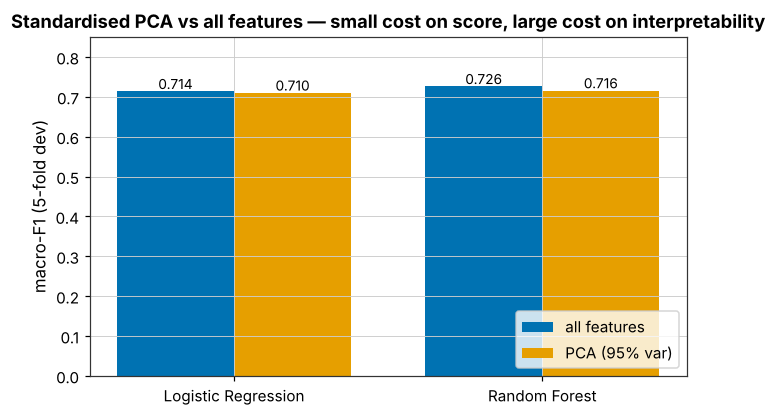

In [11]:
pca_cmp = (cv_all[cv_all.variant.isin(["all features", "pca"])]
           .pivot(index="model", columns="variant", values="f1_macro").round(4))
pca_cmp["delta (pca - all)"] = (pca_cmp["pca"] - pca_cmp["all features"]).round(4)
print("macro-F1, all features vs PCA (5-fold dev):\n")
print(pca_cmp.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
models = pca_cmp.index.tolist(); x = np.arange(len(models)); w = 0.38
ax.bar(x - w/2, pca_cmp["all features"], w, label="all features", color=viz.OKABE_ITO["blue"])
ax.bar(x + w/2, pca_cmp["pca"], w, label="PCA (95% var)", color=viz.OKABE_ITO["orange"])
for i, m in enumerate(models):
    ax.text(i - w/2, pca_cmp["all features"][m] + 0.006, f"{pca_cmp['all features'][m]:.3f}",
            ha="center", fontsize=9)
    ax.text(i + w/2, pca_cmp["pca"][m] + 0.006, f"{pca_cmp['pca'][m]:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(models); ax.set_ylim(0, 0.85)
ax.set_ylabel("macro-F1 (5-fold dev)")
ax.set_title("Standardised PCA vs all features — small cost on score, large cost on interpretability")
ax.legend(loc="lower right")
fig.savefig(FIGURES / "05_pca_comparison.png")
plt.show()

## 7 · Save the final-test results

In [12]:
final_all = pd.concat([final3.assign(task="multiclass"),
                       finalb.assign(task="binary")], ignore_index=True)
final_all.to_csv(PROC / "final_test_results.csv", index=False)
print("written: data/processed/final_test_results.csv")
print("\nheadline numbers for the report:")
for _, r in final3[final3.model != "Majority baseline"].iterrows():
    print(f"  {r['model']:22s} test accuracy {r['accuracy']:.3f} | macro-F1 {r['f1_macro']:.3f} | MCC {r['mcc']:.3f}")

written: data/processed/final_test_results.csv

headline numbers for the report:
  Logistic Regression    test accuracy 0.722 | macro-F1 0.683 | MCC 0.570
  Random Forest          test accuracy 0.758 | macro-F1 0.714 | MCC 0.614


## 8 · Discussion and conclusion

**Which model, and why.** On the sealed test set the two algorithms finish close together, with
Random Forest a little ahead on overall accuracy and macro-F1 and Logistic Regression competitive
on the minority *Enrolled* class and on ROC/PR for the binary problem. Neither margin is large
enough, on 885 rows, to call one model decisively better on score alone.

**The deciding factor is therefore not accuracy but use.** The task is an *early-warning* system
for a student-support office, and an office has to act on a prediction and justify the action.
Logistic Regression hands it a reason — "this student's odds of dropping out are raised most by
an unpaid tuition balance and a low first-semester approval rate" — while the Random Forest hands
it a ranked list of features with no direction. For deployment we recommend **Logistic Regression
as the operational model**, with the Random Forest kept as the accuracy benchmark and as an
independent check on which features matter.

**What the comparison shows about the data.** Both models rank the same academic-progress features
at the top, matching the descriptor paper's five cross-algorithm features, which is strong evidence
the signal is real rather than an artefact of either method. They disagree most where the forest's
impurity importance is inflated by high-cardinality encodings — a limitation to state, not to hide.

**How accuracy could be improved (rubric criterion 7).** Probability calibration before choosing a
threshold; a cost-sensitive threshold tied to the office's real follow-up capacity rather than best
F1; treating the ordered outcome as ordinal rather than nominal; stacking the two models, whose
per-class strengths are complementary; and collecting features the dataset lacks, such as
attendance and assessment timing.

**Limitations.** The *Enrolled* class stays the weakest for both models — it is small and genuinely
ambiguous (a student behind schedule). The early-warning variant costs roughly three points of
macro-F1, the honest price of acting a semester sooner. And the data is from one Portuguese
institution between 2008 and 2019, so the coefficients should be re-estimated before use elsewhere.